# Interpretability 8: Adding auxiliary variables

When we do a regression task, it might be good to include auxiliary input variables, even though they might be dependent on other variables. For example, to regress $m(m_0, v, c)=m_0/\sqrt{1-(v/c)^2}$, it is desirable to include the dimensionaless varabile $\beta = v/c$ as a separate input variable. If we also know this is a task in relativity, we may also include $\gamma=1/\sqrt{1-(v/c)^2}$ because $\gamma$ appears frequently in relativity.

In [1]:
from sympy import *
import torch
from xkan import KANNetwork, fit
from xkan.interp import prune
from xkan.symbolic import auto_symbolic, symbolic_formula
from xkan.utils import create_dataset, augment_input
from xkan.viz import plot

seed = 1
torch.manual_seed(seed)
torch.set_default_dtype(torch.float64)

input_variables = m0, v, c = symbols('m0 v c')

# define auxillary variables
beta = v/c
gamma = 1/sqrt(1-beta**2)

aux_vars = (beta, gamma)

f = lambda x: x[:,[0]]/torch.sqrt(1-x[:,[1]]**2/x[:,[2]]**2)
train, test = create_dataset(f, n_var=3, ranges=[[0,1],[0,0.9],[1.1,2]])

# add auxillary variables
train['x'] = augment_input(input_variables, aux_vars, train['x'])
test['x'] = augment_input(input_variables, aux_vars, test['x'])
input_variables = aux_vars + input_variables

In [2]:
model = KANNetwork([5,[0,1]], mult_arity=2, grid=3, k=3, seed=seed)

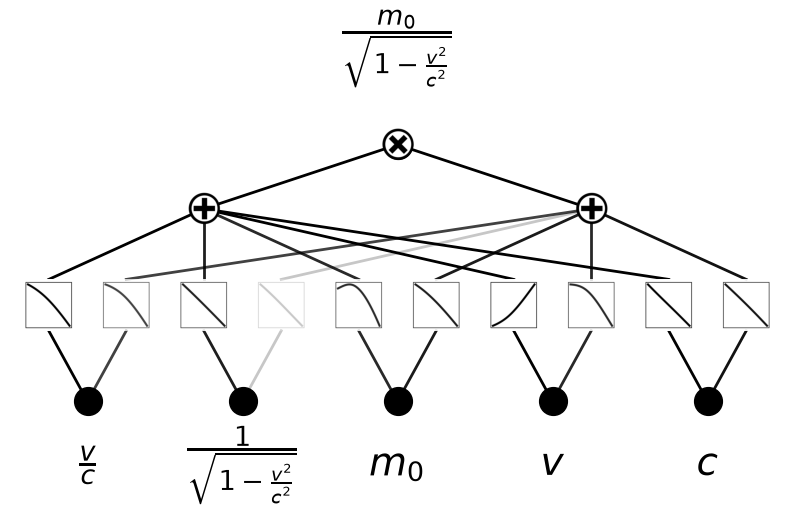

In [3]:
plot(model, train['x'], in_vars=input_variables, out_vars=[m0/sqrt(1-v**2/c**2)], scale=1.0, varscale=0.7);

In [4]:
history = fit(model, train, test, steps=50, lamb=1e-5, lamb_coef=1.0)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)

train RMSE 0.0004718022255637852 test RMSE 0.0005491616158888155


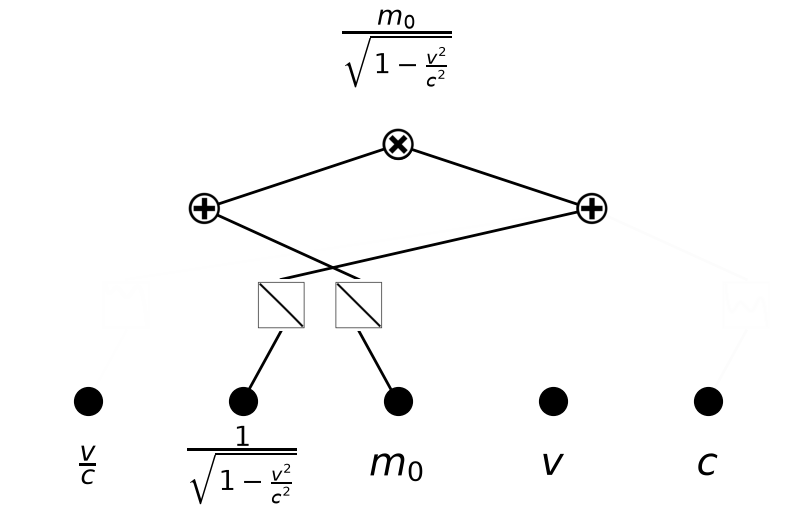

In [5]:
plot(model, train['x'], in_vars=input_variables, out_vars=[m0/sqrt(1-v**2/c**2)], scale=1.0, varscale=0.7);

In [6]:
model = prune(model, train['x'], edge_th=5e-2)

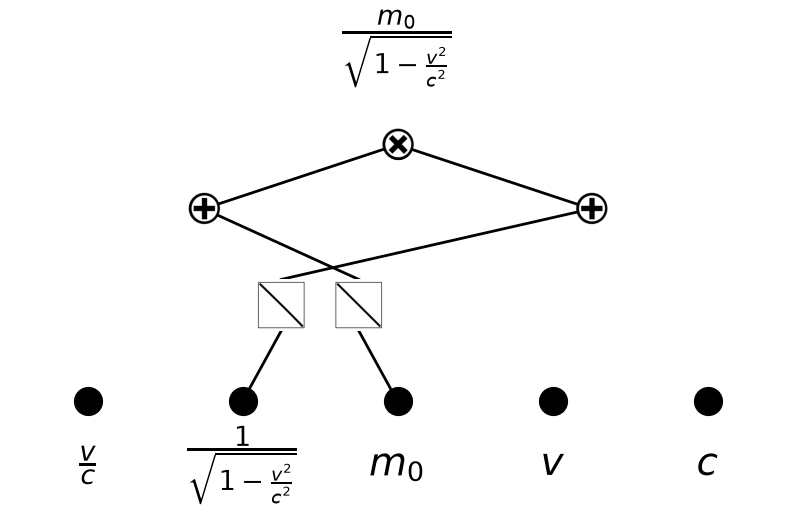

In [7]:
plot(model, train['x'], in_vars=input_variables, out_vars=[m0/sqrt(1-v**2/c**2)], scale=1.0, varscale=0.7);

In [8]:
history = fit(model, train, test, steps=100, lamb=0e-3)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)

train RMSE 3.604159812044775e-06 test RMSE 4.150031327080983e-06


In [9]:
auto_symbolic(model, train['x']);

fixing (0,0,0) with 0
fixing (0,0,1) with 0


fixing (0,1,0) with 0
fixing (0,2,1) with 0


fixing (0,3,0) with 0
fixing (0,3,1) with 0


fixing (0,4,0) with 0
fixing (0,4,1) with 0


fixing (0,1,1) with x, r2=0.99999998729077, c=1


fixing (0,2,0) with x, r2=0.9999999997439032, c=1


In [10]:
sf = symbolic_formula(model, var=input_variables)[0][0]
sf

1.0*(7.83806863080549e-7 - 1.07690811998786/sqrt(1 - v**2/c**2))*(-0.928584841000856*m0 - 4.47017799035457e-8)

In [11]:
from xkan.utils import ex_round

nsimplify(ex_round(ex_round(ex_round(sf,6),3),3))

m0/sqrt(1 - v**2/c**2)